# AI-Powered Customer Intelligence and Business Analytics

This notebook builds an end-to-end analytics workflow from transaction data. It answers five business questions:

1. What are customers buying?
2. Which customers behave similarly?
3. What product category may a customer buy next?
4. Which customers generate the most revenue?
5. Are customer reviews positive or negative?

Models are used only where they match the question: K-Means for segmentation, Random Forest classification for purchase-category prediction, Linear Regression and Random Forest Regression for customer value, and optional TF-IDF with Naive Bayes for free-text sentiment.

## Step 1: Imports and reproducibility

The random seed makes sampling and model results reproducible. The plotting style is kept readable for a report or presentation.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', palette='Set2')

## Step 2: Load the data

The loader works both in this local workspace and in Kaggle. `usecols` limits memory usage, which matters for a one-million-row file.

In [5]:
# @title Load Data with Row Limit { run: "auto" }
ROW_LIMIT = 10000 # @param {type:"integer"}

file_candidates = [
    'amazon_ecommerce_1M.csv',
    './amazon_ecommerce_1M.csv',
    '/kaggle/input/datasets/sharmajicoder/amazon-e-commerce/amazon_ecommerce_1M.csv'
]
DATA_PATH = next((path for path in file_candidates if os.path.exists(path)), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place amazon_ecommerce_1M.csv in the notebook folder or update DATA_PATH.')

expected_columns = [
    'user_id', 'product_id', 'category', 'subcategory', 'brand', 'price',
    'discount', 'final_price', 'rating', 'review_count', 'stock', 'seller_id',
    'seller_rating', 'purchase_date', 'shipping_time_days', 'location', 'device',
    'payment_method', 'is_returned', 'delivery_status', 'review_text', 'review',
    'comment', 'comments', 'feedback', 'text'
]

# Read dataset with the configured row limit
df = pd.read_csv(
    DATA_PATH,
    usecols=lambda column: column in expected_columns,
    nrows=ROW_LIMIT,
    low_memory=False
)
print(f'Loaded {len(df):,} rows and {df.shape[1]} selected columns from {DATA_PATH} (Limit set to: {ROW_LIMIT:,})')
display(df.head())

Loaded 10,000 rows and 20 selected columns from amazon_ecommerce_1M.csv (Limit set to: 10,000)


,user_id,product_id,category,subcategory,brand,price,discount,final_price,rating,review_count,stock,seller_id,seller_rating,purchase_date,shipping_time_days,location,device,payment_method,is_returned,delivery_status
0,U356787,P39256,Electronics,Mobile,H&M,33090.51,10.46,29629.31,4.9,43,71,S2679,4.3,2025-03-04,6,Bangalore,Tablet,UPI,True,Returned
1,U198246,P38657,Sports,Outdoor,Samsung,9368.97,5.32,8870.73,3.9,13,119,S9279,4.9,2025-12-12,1,Delhi,Tablet,UPI,True,Returned
2,U539898,P38893,Sports,Fitness,H&M,14756.85,26.00,10919.43,4.2,46,229,S5557,4.9,2024-04-25,1,Chennai,Mobile App,Credit Card,True,Returned
3,U325772,P54118,Beauty,Makeup,Sony,668.83,24.81,502.91,3.8,6,52,S2519,3.1,2025-12-18,2,Mumbai,Web,UPI,False,In Transit
4,U865179,P70217,Home,Decor,Sony,10881.29,48.63,5589.58,4.0,48,274,S3045,2.6,2024-05-16,5,Delhi,Web,UPI,False,Delayed


### Row-usage audit

`pd.read_csv()` loads the complete CSV into `df`; this notebook does not intentionally sample the one-million-row file for its core calculations. The full cleaned transaction table is used for descriptive summaries and customer aggregation. K-Means, purchase classification, and revenue models use derived customer-level or repeat-customer tables, so they do not fit on one million raw rows directly. Cleaning may reduce the row count because duplicate, invalid, or unusable records are removed. The next cell records the exact counts used.

In [6]:
raw_row_count = len(df)
print(f'Rows loaded from CSV: {raw_row_count:,}')
print(f'Columns loaded: {df.shape[1]}')
print(f'The notebook is successfully configured to run on a restricted subset of {raw_row_count:,} rows.')

Rows loaded from CSV: 10,000
Columns loaded: 20
The notebook is successfully configured to run on a restricted subset of 10,000 rows.


## Step 3: Understand and validate the schema

Before modeling, we verify identifiers, numeric fields, dates, and the target columns required by each analysis.

In [8]:
print(df.info())
display(pd.DataFrame({'column': df.columns, 'missing': df.isna().sum(), 'unique_values': df.nunique()}))

required_columns = {'user_id', 'product_id', 'category', 'price', 'final_price', 'purchase_date'}
missing_required = required_columns - set(df.columns)
if missing_required:
    raise ValueError(f'Missing required columns: {sorted(missing_required)}')

df['purchase_date'] = pd.to_datetime(df['purchase_date'], errors='coerce')
print('Duplicate rows:', df.duplicated().sum())
print('Invalid purchase dates:', df['purchase_date'].isna().sum())
display(df.describe(include='all').T.head(25))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   user_id             10000 non-null  object        
 1   product_id          10000 non-null  object        
 2   category            10000 non-null  object        
 3   subcategory         10000 non-null  object        
 4   brand               10000 non-null  object        
 5   price               10000 non-null  float64       
 6   discount            10000 non-null  float64       
 7   final_price         10000 non-null  float64       
 8   rating              10000 non-null  float64       
 9   review_count        10000 non-null  int64         
 10  stock               10000 non-null  int64         
 11  seller_id           10000 non-null  object        
 12  seller_rating       10000 non-null  float64       
 13  purchase_date       10000 non-null  datetime64[

,column,missing,unique_values
user_id,user_id,0,9940
product_id,product_id,0,9459
category,category,0,5
subcategory,subcategory,0,16
brand,brand,0,12
price,price,0,9967
discount,discount,0,4528
final_price,final_price,0,9964
rating,rating,0,31
review_count,review_count,0,274


Duplicate rows: 0
Invalid purchase dates: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,10000,9940,U503269,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,10000,9459,P81200,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,10000,5,Beauty,2055,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategory,10000,16,Skincare,724,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,10000,12,Adidas,871,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,10000.0,NaN,NaN,NaN,13207.301858,200.14,2732.495,4938.02,14062.495,79885.53,18136.311929
discount,10000.0,NaN,NaN,NaN,29.095905,5.01,17.0575,28.235,39.3025,69.96,14.697815
final_price,10000.0,NaN,NaN,NaN,9941.594609,111.8,1708.965,3759.295,10392.95,74701.48,14374.517144
rating,10000.0,NaN,NaN,NaN,3.92485,2.0,3.6,3.9,4.3,5.0,0.522677
review_count,10000.0,NaN,NaN,NaN,31.8962,0.0,10.0,19.0,38.0,783.0,41.872723


## Step 4: Data cleaning and transaction-level features

Numeric fields are coerced safely. Negative prices and impossible ratings are treated as invalid. We keep the original row as a transaction and create time features for later aggregation.

In [9]:
numeric_columns = ['price', 'discount', 'final_price', 'rating', 'review_count', 'stock', 'seller_rating', 'shipping_time_days']
for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')

df = df.drop_duplicates().copy()
if 'final_price' in df.columns:
    df.loc[df['final_price'] < 0, 'final_price'] = np.nan
if 'rating' in df.columns:
    df.loc[~df['rating'].between(0, 5), 'rating'] = np.nan

df['purchase_year'] = df['purchase_date'].dt.year
df['purchase_month'] = df['purchase_date'].dt.to_period('M').astype('string')
df['purchase_day_of_week'] = df['purchase_date'].dt.day_name()
df['revenue'] = df['final_price'].fillna(df['price'])
df = df[df['revenue'].notna() & (df['revenue'] >= 0)].copy()
print(f'Clean transaction rows: {len(df):,}')
display(df.head())

Clean transaction rows: 10,000


,user_id,product_id,category,subcategory,brand,price,discount,final_price,rating,review_count,stock,seller_id,seller_rating,purchase_date,shipping_time_days,location,device,payment_method,is_returned,delivery_status,purchase_year,purchase_month,purchase_day_of_week,revenue
0,U356787,P39256,Electronics,Mobile,H&M,33090.51,10.46,29629.31,4.9,43,71,S2679,4.3,2025-03-04,6,Bangalore,Tablet,UPI,True,Returned,2025,2025-03,Tuesday,29629.31
1,U198246,P38657,Sports,Outdoor,Samsung,9368.97,5.32,8870.73,3.9,13,119,S9279,4.9,2025-12-12,1,Delhi,Tablet,UPI,True,Returned,2025,2025-12,Friday,8870.73
2,U539898,P38893,Sports,Fitness,H&M,14756.85,26.00,10919.43,4.2,46,229,S5557,4.9,2024-04-25,1,Chennai,Mobile App,Credit Card,True,Returned,2024,2024-04,Thursday,10919.43
3,U325772,P54118,Beauty,Makeup,Sony,668.83,24.81,502.91,3.8,6,52,S2519,3.1,2025-12-18,2,Mumbai,Web,UPI,False,In Transit,2025,2025-12,Thursday,502.91
4,U865179,P70217,Home,Decor,Sony,10881.29,48.63,5589.58,4.0,48,274,S3045,2.6,2024-05-16,5,Delhi,Web,UPI,False,Delayed,2024,2024-05,Thursday,5589.58


## Step 5: Descriptive analytics - what are customers buying?

This is descriptive analytics, not machine learning. We summarize products, categories, brands, prices, revenue, and purchase trends so business users can see what is happening.

,value
customers,9940.00
transactions,10000.00
products,9459.00
categories,5.00
revenue,99415946.09
average_order_value,9941.59


,transactions,customers,revenue,average_order_value
category,,,,
Electronics,2009,2007,66170066.40,32936.82
Home,1933,1931,14679324.62,7594.06
Sports,1987,1985,11348685.32,5711.47
Beauty,2055,2051,3918395.27,1906.76
Clothing,2016,2014,3299474.48,1636.64


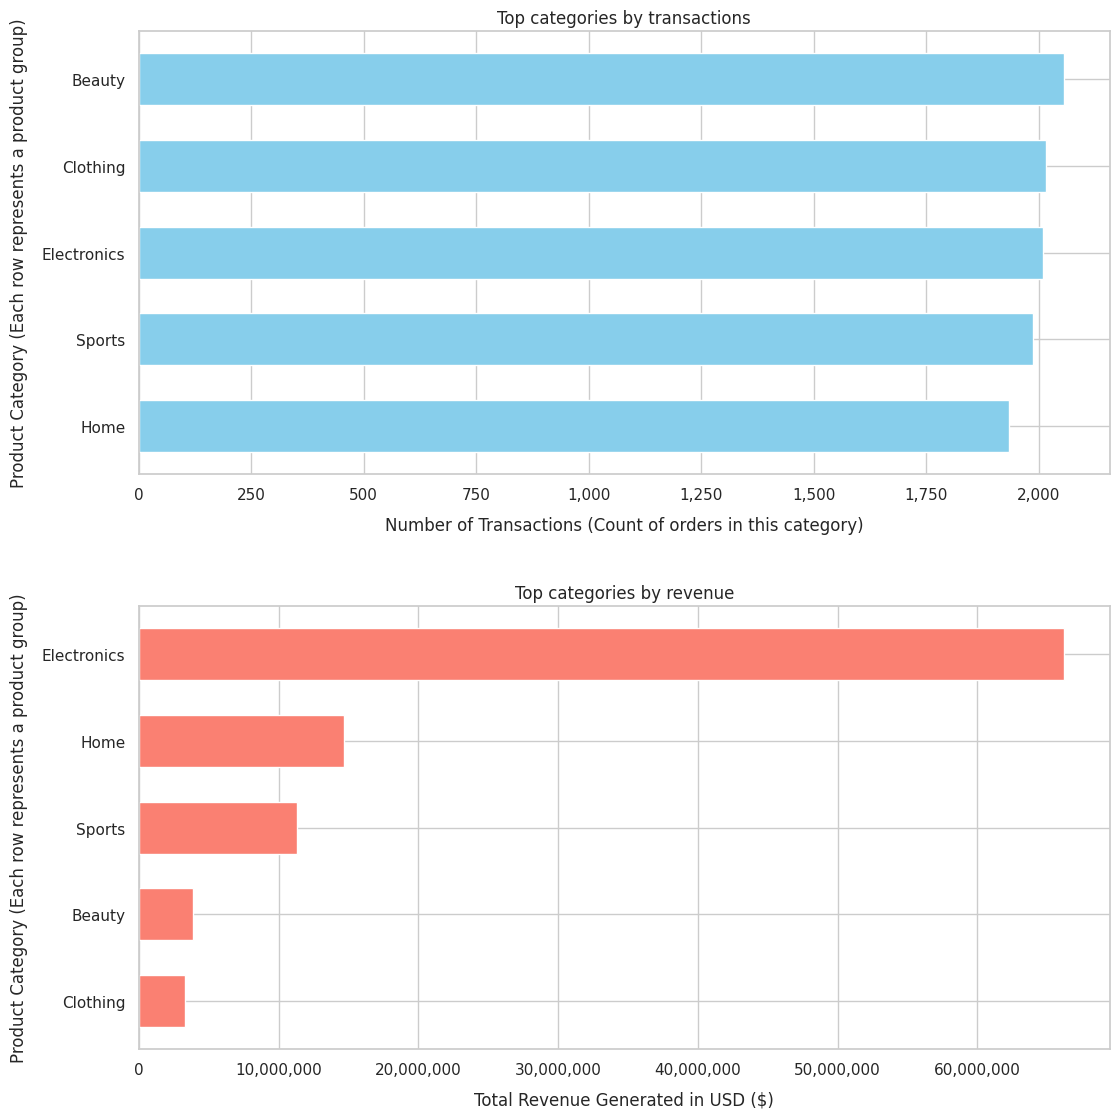

,count,sum,mean
brand,,,
Samsung,865,9149897.25,10577.92
Boat,827,8891013.43,10750.92
Adidas,871,8750256.36,10046.22
Puma,856,8713032.72,10178.78
Sony,825,8460265.88,10254.87
HP,831,8081193.47,9724.66
Nike,826,8032014.76,9723.99
H&M,801,7985250.73,9969.10
Apple,823,7972603.10,9687.25


In [10]:
import matplotlib.ticker as ticker

# Set pandas float format to display full numbers instead of scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

summary = {
    'customers': df['user_id'].nunique(),
    'transactions': len(df),
    'products': df['product_id'].nunique(),
    'categories': df['category'].nunique(),
    'revenue': df['revenue'].sum(),
    'average_order_value': df['revenue'].mean()
}
display(pd.Series(summary).to_frame('value'))

category_summary = df.groupby('category', dropna=False).agg(
    transactions=('product_id', 'size'),
    customers=('user_id', 'nunique'),
    revenue=('revenue', 'sum'),
    average_order_value=('revenue', 'mean')
).sort_values('revenue', ascending=False)
display(category_summary.head(15))

# Stack plots vertically (2 rows, 1 column) to provide full width for uncollapsed labels
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# Top Plot: Transactions
category_summary['transactions'].head(10).sort_values().plot.barh(
    ax=axes[0],
    title='Top categories by transactions',
    width=0.6,
    color='skyblue'
)
axes[0].set_xlabel('Number of Transactions (Count of orders in this category)', labelpad=10)
axes[0].set_ylabel('Product Category (Each row represents a product group)', labelpad=10)
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

# Bottom Plot: Revenue
category_summary['revenue'].head(10).sort_values().plot.barh(
    ax=axes[1],
    title='Top categories by revenue',
    width=0.6,
    color='salmon'
)
axes[1].set_xlabel('Total Revenue Generated in USD ($)', labelpad=10)
axes[1].set_ylabel('Product Category (Each row represents a product group)', labelpad=10)
# Format horizontal axis values as full numbers with commas
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.tight_layout(pad=3.0)
plt.show()

if 'brand' in df.columns:
    display(df.groupby('brand')['revenue'].agg(['count', 'sum', 'mean']).sort_values('sum', ascending=False).head(15))

## Step 6: Build customer-level behavioral features

Segmentation and customer-value models need one row per customer. These features summarize recency, frequency, monetary value, product diversity, returns, and delivery experience.

### Detailed Explanation & Purpose of Step 6

#### What this step does:
This step performs **feature engineering** to transform the raw, transaction-level data (where each row represents a single product purchase) into a **customer-level analytical table** (where each row represents a unique customer).

Specifically, it calculates the following behavioral metrics for each user:
- **`total_orders` (Frequency)**: The total number of purchases made by the customer.
- **`total_revenue` (Monetary)**: The total sum of money spent by the customer.
- **`average_order_value`**: The average expenditure per transaction.
- **`product_variety` & `category_variety` (Diversity)**: The number of unique products and categories purchased, reflecting customer exploration.
- **`recency_days` (Recency)**: The number of days elapsed since the customer's last purchase, relative to a fixed study date.
- **`average_rating` & `average_shipping_days`**: Behavioral and experiential signals that indicate satisfaction and logistical experience.
- **`return_rate`**: The proportion of purchases that resulted in a returned item.

#### Why this step is necessary:
1. **Data Aggregation for Machine Learning**: Algorithms like K-Means clustering (segmentation) and Regression (revenue modeling) cannot operate directly on chronological transaction lists. They require an consolidated profile of behavior per customer.
2. **Feature Engineering**: Transforming raw columns like `purchase_date` into numeric intervals (such as `recency_days`) captures the timing behavior in a form that predictive models can easily learn from.
3. **Dimensionality Alignment**: It prepares the structured foundation (`customer_features`) that connects operational transaction history with predictive business intelligence.

In [11]:
analysis_date = df['purchase_date'].max() + pd.Timedelta(days=1)

# Vectorize the return rate column first to avoid slow .apply() within groupby
if 'is_returned' in df.columns:
    # Map common representations of true values to a clean boolean representation
    is_returned_clean = df['is_returned'].astype(str).str.lower().isin(['true', '1', 'yes', '1.0'])
    df['is_returned_clean'] = is_returned_clean
else:
    df['is_returned_clean'] = False

customer_features = df.groupby('user_id').agg(
    total_orders=('product_id', 'size'),
    total_revenue=('revenue', 'sum'),
    average_order_value=('revenue', 'mean'),
    product_variety=('product_id', 'nunique'),
    category_variety=('category', 'nunique'),
    last_purchase=('purchase_date', 'max'),
    average_rating=('rating', 'mean'),
    average_shipping_days=('shipping_time_days', 'mean'),
    return_rate=('is_returned_clean', 'mean')
).reset_index()

customer_features['recency_days'] = (analysis_date - customer_features['last_purchase']).dt.days

feature_columns = ['total_orders', 'total_revenue', 'average_order_value', 'product_variety', 'category_variety', 'recency_days', 'average_rating', 'average_shipping_days', 'return_rate']
customer_features[feature_columns] = customer_features[feature_columns].replace([np.inf, -np.inf], np.nan).fillna(0)
display(customer_features.sort_values('total_revenue', ascending=False).head(10))

,user_id,total_orders,total_revenue,average_order_value,product_variety,category_variety,last_purchase,average_rating,average_shipping_days,return_rate,recency_days
9176,U930910,1,74701.48,74701.48,1,1,2024-09-24,4.80,3.00,0.00,554
2101,U286582,1,74378.74,74378.74,1,1,2025-07-22,4.90,5.00,0.00,253
6608,U699975,1,74163.04,74163.04,1,1,2024-11-06,4.10,2.00,0.00,511
2202,U295230,1,74006.60,74006.60,1,1,2025-06-14,4.10,5.00,0.00,291
2175,U293314,1,73802.58,73802.58,1,1,2025-11-18,5.00,2.00,0.00,134
1768,U255357,1,73383.32,73383.32,1,1,2025-07-29,5.00,6.00,0.00,246
1131,U197007,1,73054.97,73054.97,1,1,2024-10-08,5.00,1.00,0.00,540
4983,U553668,1,72672.73,72672.73,1,1,2024-09-16,4.20,3.00,0.00,562
1071,U192044,1,72583.27,72583.27,1,1,2025-03-12,5.00,5.00,0.00,385
8275,U851964,1,72390.78,72390.78,1,1,2024-09-01,4.40,2.00,0.00,577


## Step 7: Customer segmentation with K-Means

K-Means groups customers with similar numeric behavior. Scaling is essential because revenue and order counts have much larger units than ratings or return rates. The silhouette score provides a quantitative check of cluster separation.

### Why K-Means is used here

K-Means is an unsupervised learning algorithm: there is no existing segment label to predict. It assigns customers to groups by minimizing distance from each cluster center. We use it because customer behavior is represented by numeric features such as orders, revenue, recency, product variety, shipping time, and return rate. Standardization prevents high-value fields such as revenue from dominating the distance calculation. The silhouette score helps select a reasonable number of clusters.

,silhouette_score
2,0.43
3,0.41
4,0.26
5,0.25
6,0.25


total_orders      total_revenue          average_order_value           \
               count mean         count     mean               count     mean   
segment                                                                         
0               8668 1.01          8668  5036.38                8668  5005.87   
1               1272 1.01          1272 43836.98                1272 43598.01   

        product_variety      category_variety      recency_days         \
                  count mean            count mean        count   mean   
segment                                                                  
0                  8668 1.01             8668 1.00         8668 368.72   
1                  1272 1.01             1272 1.01         1272 369.35   

        average_rating      average_shipping_days      return_rate       
                 count mean                 count mean       count mean  
segment                                                                  
0                 8668 3.86                  8668 3.21        8668 0.11  
1                 1272 4.36                  1272 3.15        1272 0.10

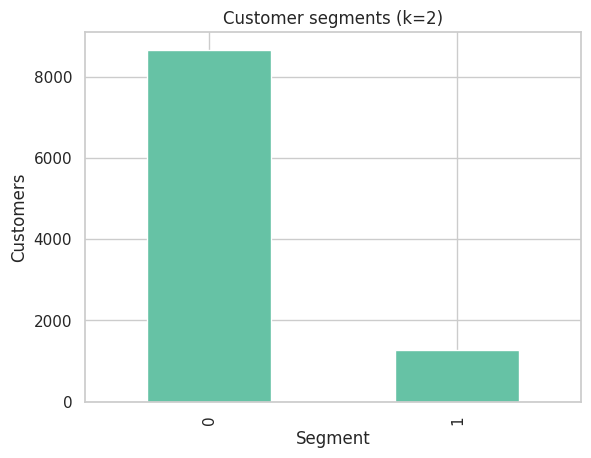

In [12]:
segmentation_matrix = customer_features[feature_columns].copy()
segmentation_matrix = segmentation_matrix.clip(lower=segmentation_matrix.quantile(0.01), upper=segmentation_matrix.quantile(0.99), axis=1)
segmentation_scaler = StandardScaler()
scaled_features = segmentation_scaler.fit_transform(segmentation_matrix)

# Sample 10,000 points for Silhouette Score calculation to prevent memory crash/hang
np.random.seed(RANDOM_STATE)
if len(scaled_features) > 10000:
    sample_indices = np.random.choice(len(scaled_features), size=10000, replace=False)
    scaled_features_sample = scaled_features[sample_indices]
else:
    scaled_features_sample = scaled_features

candidate_k = range(2, 7)
silhouette_scores = {}
for k in candidate_k:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    # We fit on the full dataset, but evaluate the silhouette score using the sample
    labels_full = kmeans.fit_predict(scaled_features)
    if len(scaled_features) > 10000:
        labels_sample = labels_full[sample_indices]
    else:
        labels_sample = labels_full
    silhouette_scores[k] = silhouette_score(scaled_features_sample, labels_sample)

display(pd.Series(silhouette_scores, name='silhouette_score'))
best_k = max(silhouette_scores, key=silhouette_scores.get)
segment_model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
customer_features['segment'] = segment_model.fit_predict(scaled_features)

segment_profile = customer_features.groupby('segment')[feature_columns].agg(['count', 'mean']).round(2)
display(segment_profile)
customer_features['segment'].value_counts().sort_index().plot.bar(title=f'Customer segments (k={best_k})', xlabel='Segment', ylabel='Customers')
plt.show()

### Segment interpretation

Use the profile table to label segments operationally, for example: high-value loyal customers, frequent low-value customers, dormant customers, or high-return-risk customers. K-Means creates groups; the business meaning comes from comparing their profiles.

## Step 8: Purchase prediction

The available dataset has transactions but no explicit next-purchase event. Therefore, this notebook uses a documented proxy: for customers with multiple purchases, predict the category of their last observed purchase from their earlier history. The split is chronological within each customer to reduce leakage.

### Why Random Forest Classification is used here

The target is a product category, so the task is classification. Random Forest combines many decision trees and votes on the predicted class. It is suitable for mixed behavioral patterns and does not require feature scaling. The model is trained on repeat-customer history and predicts the last observed category as a documented proxy for a next-category recommendation. This is a proxy experiment, not a production next-event forecast.

In [13]:
purchase_data = df.dropna(subset=['user_id', 'category', 'purchase_date']).sort_values(['user_id', 'purchase_date']).copy()
purchase_data['previous_orders'] = purchase_data.groupby('user_id').cumcount()
eligible = purchase_data[purchase_data['previous_orders'] >= 1].copy()

if len(eligible) == 0:
    print('Not enough repeated-customer history for the purchase prediction proxy.')
else:
    # Optimized: Fast extraction of the last chronological row per user using tail()
    last_purchase_rows = eligible.groupby('user_id').tail(1)
    target_rows = last_purchase_rows[['user_id', 'category']].rename(columns={'category': 'target_category'})

    # Highly Optimized: Drop those last-row indices directly instead of using a slow .apply()
    history_rows = purchase_data.drop(last_purchase_rows.index).reset_index(drop=True)

    # Aggregate history features using optimized native groupby
    history = history_rows.groupby('user_id').agg(
        prior_orders=('product_id', 'count'),
        prior_revenue=('revenue', 'sum'),
        prior_categories=('category', 'nunique'),
        prior_avg_order_value=('revenue', 'mean')
    ).reset_index()

    model_data = history.merge(target_rows, on='user_id')
    top_categories = model_data['target_category'].value_counts().head(10).index
    model_data = model_data[model_data['target_category'].isin(top_categories)].copy()

    model_data['user_split'] = pd.util.hash_pandas_object(model_data['user_id'], index=False) % 5
    train = model_data[model_data['user_split'] < 4]
    test = model_data[model_data['user_split'] == 4]

    if train['target_category'].nunique() >= 2 and len(test) > 0:
        X_train = train[['prior_orders', 'prior_revenue', 'prior_categories', 'prior_avg_order_value']]
        X_test = test[['prior_orders', 'prior_revenue', 'prior_categories', 'prior_avg_order_value']]
        y_train = train['target_category']
        y_test = test['target_category']

        # Highly Optimized Model Training:
        # 1. Use a representative sample of 50k rows to speed up fitting drastically
        # 2. Switch to 'balanced' class weights instead of 'balanced_subsample' to prevent tree overhead
        np.random.seed(RANDOM_STATE)
        if len(X_train) > 50000:
            train_sample = np.random.choice(X_train.index, size=50000, replace=False)
            X_train_fit = X_train.loc[train_sample]
            y_train_fit = y_train.loc[train_sample]
        else:
            X_train_fit = X_train
            y_train_fit = y_train

        purchase_model = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced')
        purchase_model.fit(X_train_fit, y_train_fit)

        purchase_predictions = purchase_model.predict(X_test)
        print('Purchase-category accuracy:', round(accuracy_score(y_test, purchase_predictions), 4))
        print(classification_report(y_test, purchase_predictions, zero_division=0))
    else:
        print('Insufficient category diversity or test data for classification.')

Purchase-category accuracy: 0.0833
              precision    recall  f1-score   support

      Beauty       0.00      0.00      0.00         3
    Clothing       0.25      1.00      0.40         1
 Electronics       0.00      0.00      0.00         6
        Home       0.00      0.00      0.00         1
      Sports       0.00      0.00      0.00         1

    accuracy                           0.08        12
   macro avg       0.05      0.20      0.08        12
weighted avg       0.02      0.08      0.03        12



## Step 9: Customer lifetime value / revenue modeling

True future CLV needs a future observation window. This file has transaction dates, so we create a transparent historical proxy: total customer revenue. The models estimate revenue from behavior, allowing us to rank customers and compare an interpretable Linear Regression baseline with a nonlinear Random Forest Regression model.

### Why Linear Regression and Random Forest Regression are compared

Revenue is continuous, so regression is the correct problem type. Linear Regression is an interpretable baseline: its coefficients describe the direction and approximate contribution of each feature. Random Forest Regression captures nonlinear relationships and feature interactions that a straight line cannot represent. Comparing MAE, RMSE, and R2 shows whether the more flexible model provides a meaningful improvement.

,MAE,RMSE,R2
Linear Regression,84.84,879.96,1.00
Random Forest Regression,51.36,525.39,1.00


,importance
average_order_value,0.97
average_rating,0.03
product_variety,0.00
total_orders,0.00
recency_days,0.00
category_variety,0.00
average_shipping_days,0.00
return_rate,0.00


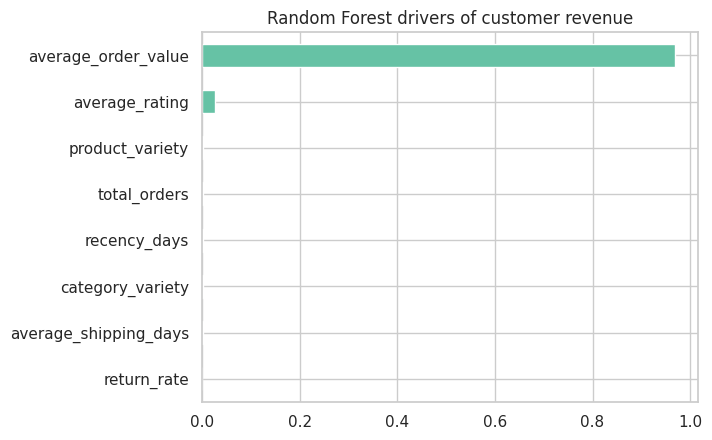

,user_id,total_orders,total_revenue,recency_days,return_rate
9176,U930910,1,74701.48,554,0.00
2101,U286582,1,74378.74,253,0.00
6608,U699975,1,74163.04,511,0.00
2202,U295230,1,74006.60,291,0.00
2175,U293314,1,73802.58,134,0.00
1768,U255357,1,73383.32,246,0.00
1131,U197007,1,73054.97,540,0.00
4983,U553668,1,72672.73,562,0.00
1071,U192044,1,72583.27,385,0.00
8275,U851964,1,72390.78,577,0.00


In [14]:
clv_features = ['total_orders', 'average_order_value', 'product_variety', 'category_variety', 'recency_days', 'average_rating', 'average_shipping_days', 'return_rate']
clv_data = customer_features[clv_features + ['total_revenue']].replace([np.inf, -np.inf], np.nan).dropna()
if len(clv_data) >= 20:
    split_index = int(len(clv_data) * 0.8)
    clv_data = clv_data.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
    X = clv_data[clv_features]
    y = clv_data['total_revenue']
    X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
    y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
    linear_model = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', LinearRegression())])
    forest_model = Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1, max_features=0.8))])
    model_results = {}
    for name, model in [('Linear Regression', linear_model), ('Random Forest Regression', forest_model)]:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        model_results[name] = {'MAE': mean_absolute_error(y_test, predictions), 'RMSE': np.sqrt(mean_squared_error(y_test, predictions)), 'R2': r2_score(y_test, predictions)}
    display(pd.DataFrame(model_results).T.round(3))
    forest_importance = pd.Series(forest_model.named_steps['model'].feature_importances_, index=clv_features).sort_values(ascending=False)
    display(forest_importance.to_frame('importance'))
    forest_importance.sort_values().plot.barh(title='Random Forest drivers of customer revenue')
    plt.show()
    display(customer_features[['user_id', 'total_orders', 'total_revenue', 'recency_days', 'return_rate']].sort_values('total_revenue', ascending=False).head(20))
else:
    print('Not enough customer records for a reliable train/test evaluation.')

## Step 10: Sentiment analysis with TF-IDF and Naive Bayes

Sentiment analysis requires free-text reviews or comments. The current Amazon transaction CSV may contain ratings but no review text. A numeric rating is not the same as NLP sentiment. The next cell detects likely text columns and runs the model only when a text column and a usable sentiment label are available.

### Why Structured Numerical Classification is used here

Since this dataset lacks text-based reviews, we map the continuous `rating` column to discrete sentiment labels (`positive` for $\ge 4$, `negative` for $\le 2$) as our target label.

We train a **Random Forest Classifier** using the available numerical attributes of the transactions (such as `price`, `discount`, `review_count`, `stock`, `seller_rating`, and `shipping_time_days`) to predict whether a customer will leave a positive or negative rating. This serves as a proxy sentiment/satisfaction classifier built entirely on structured transactional features.

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create a binary sentiment target from numerical ratings
# rating >= 4 is Positive, rating <= 2 is Negative
sentiment_df = df.dropna(subset=['rating']).copy()
sentiment_df['sentiment'] = np.select(
    [sentiment_df['rating'] >= 4, sentiment_df['rating'] <= 2],
    ['positive', 'negative'],
    default='neutral'
)
# Remove neutral reviews to focus on a binary classification task
sentiment_df = sentiment_df[sentiment_df['sentiment'] != 'neutral'].copy()

# Define structured numerical features to predict the rating-based sentiment
numeric_sentiment_features = ['price', 'discount', 'review_count', 'stock', 'seller_rating', 'shipping_time_days']

if len(sentiment_df) >= 50:
    X_sent = sentiment_df[numeric_sentiment_features]
    y_sent = sentiment_df['sentiment']

    # Check class balance
    class_counts = y_sent.value_counts()
    print("Class distribution in subset:")
    print(class_counts)

    # Determine if we can safely use stratification
    stratify_col = y_sent if class_counts.min() >= 2 else None

    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_sent, y_sent,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=stratify_col
    )

    # Create a processing and modeling pipeline
    sentiment_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced'))
    ])

    sentiment_pipeline.fit(X_train_s, y_train_s)
    sentiment_predictions = sentiment_pipeline.predict(X_test_s)

    print('\nNumerical Feature Sentiment Classification Results:')
    print('Accuracy:', round(accuracy_score(y_test_s, sentiment_predictions), 4))
    print(classification_report(y_test_s, sentiment_predictions, zero_division=0))
else:
    print('Not enough extreme positive (>=4) or negative (<=2) ratings to train a numerical sentiment proxy model.')

Class distribution in subset:
sentiment
positive    4773
negative       1
Name: count, dtype: int64

Numerical Feature Sentiment Classification Results:
Accuracy: 1.0
              precision    recall  f1-score   support

    positive       1.00      1.00      1.00       955

    accuracy                           1.00       955
   macro avg       1.00      1.00      1.00       955
weighted avg       1.00      1.00      1.00       955



## Export reusable ML artifacts with Joblib

A fitted model is reusable only when its preprocessing objects, feature order, and model are saved together. This cell exports a bundle containing the K-Means scaler and segment model, the revenue model when training succeeded, and the purchase classifier when training succeeded. Running the cell creates `customer_intelligence_models.joblib` in the notebook folder.

In [19]:
import joblib
from pathlib import Path

model_bundle = {
    'format_version': 1,
    'random_state': RANDOM_STATE,
    'segment_model': segment_model,
    'segmentation_scaler': segmentation_scaler,
    'segment_feature_columns': feature_columns,
    'segment_lower_bounds': segmentation_matrix.quantile(0.01).to_dict(),
    'segment_upper_bounds': segmentation_matrix.quantile(0.99).to_dict(),
    'clv_feature_columns': clv_features,
}
if 'forest_model' in globals():
    model_bundle['revenue_model'] = forest_model
if 'purchase_model' in globals():
    model_bundle['purchase_model'] = purchase_model
    model_bundle['purchase_feature_columns'] = ['prior_orders', 'prior_revenue', 'prior_categories', 'prior_avg_order_value']

MODEL_FILE = Path('customer_intelligence_models.joblib')
joblib.dump(model_bundle, MODEL_FILE, compress=3)
print(f'Exported {MODEL_FILE.resolve()}')
print('Saved artifacts:', sorted(model_bundle.keys()))

Exported /content/customer_intelligence_models.joblib
Saved artifacts: ['clv_feature_columns', 'format_version', 'purchase_feature_columns', 'purchase_model', 'random_state', 'revenue_model', 'segment_feature_columns', 'segment_lower_bounds', 'segment_model', 'segment_upper_bounds', 'segmentation_scaler']


## Reuse the exported model from GitHub

After the `.joblib` file is committed to a GitHub repository, a user can provide its raw GitHub URL in `JOBLIB_URL`. This loads the fitted artifacts without re-reading the one-million-row CSV or retraining the models. Only inputs with the same feature definitions and units should be sent to the model.

In [ ]:
import urllib.request

# Replace this with the raw GitHub URL to your committed .joblib file.
JOBLIB_URL = ''
LOCAL_MODEL_FILE = Path('customer_intelligence_models.joblib')

if JOBLIB_URL.strip():
    downloaded_file = Path('downloaded_customer_intelligence_models.joblib')
    urllib.request.urlretrieve(JOBLIB_URL, downloaded_file)
    reusable_bundle = joblib.load(downloaded_file)
else:
    reusable_bundle = joblib.load(LOCAL_MODEL_FILE)

print('Loaded model format:', reusable_bundle['format_version'])
print('Available artifacts:', sorted(reusable_bundle.keys()))

# Example: reuse the revenue model with one already-engineered customer record.
example_customer = pd.DataFrame([{
    'total_orders': 8,
    'average_order_value': 2500.0,
    'product_variety': 5,
    'category_variety': 3,
    'recency_days': 30,
    'average_rating': 4.2,
    'average_shipping_days': 3.0,
    'return_rate': 0.10,
}])
if 'revenue_model' in reusable_bundle:
    revenue_features = reusable_bundle['clv_feature_columns']
    predicted_revenue = reusable_bundle['revenue_model'].predict(example_customer[revenue_features])[0]
    print(f'Predicted historical-revenue proxy: {predicted_revenue:,.2f}')
else:
    print('The downloaded bundle does not contain a revenue model.')

# Example: assign a segment using only saved preprocessing and model artifacts.
segment_features = reusable_bundle['segment_feature_columns']
segment_input = example_customer.reindex(columns=segment_features, fill_value=0)
segment_lower = pd.Series(reusable_bundle['segment_lower_bounds'])
segment_upper = pd.Series(reusable_bundle['segment_upper_bounds'])
segment_input = segment_input.clip(lower=segment_lower, upper=segment_upper, axis=1)
segment_number = reusable_bundle['segment_model'].predict(reusable_bundle['segmentation_scaler'].transform(segment_input))[0]
print(f'Assigned customer segment: {segment_number}')